# **PHASE 1 — NAIVE BAYES (FROM SCRATCH)**

> **Học phần:** Nhận dạng mẫu — Đồ án thực hành giữa kỳ  
> **Phương pháp:** Mô hình sinh xác suất — Multinomial Naïve Bayes tự cài đặt thuần NumPy (From Scratch).  


### **Bảng quy trình thực nghiệm Multinomial Naïve Bayes**

| Bước | Nội dung thực hiện | Đầu ra định lượng / Tệp sinh ra |
|:---:|:---|:---|
| **1.1** | **Môi trường & Nạp dữ liệu** | Nạp `data/processed/mnist_processed.npz`, trích xuất `X_train_minmax`, `X_val_minmax`, `X_test_minmax` $[0, 1]$. |
| **1.2** | **Cơ sở lý thuyết & Biện luận** | Luận điểm chọn Multinomial thay vì Gaussian; giải phẫu công thức toán học và làm mượt Laplace. |
| **1.3** | **Cài đặt thuần NumPy (From Scratch)** | Hàm `multinomial_log_pdf`, lớp `NaiveBayes`và Unit test kiểm chứng toán học. |
| **1.4** | **Tinh chỉnh siêu tham số Laplace $\alpha$** | Quét $\alpha \in [10^{-6}, \dots, 100.0]$ trên tập Validation; Biểu đồ `figures/1_01_laplace_alpha_tuning.png`. |
| **1.5** | **Đối chiếu Scikit-Learn** | Kiểm chứng chéo với `MultinomialNB(alpha=0.0001)`; khẳng định chênh lệch sai số $< 0.1\%$. |
| **1.6** | **Đánh giá toàn diện 3 tập dữ liệu** | Bảng 6 chỉ số; 3 Ma trận nhầm lẫn (`1_02`, `1_03`, `1_04`); Bảng 10 chữ số; Mẫu phân loại sai `1_05`. |
| **1.7** | **Nhận xét định lượng & Thảo luận** | Biện luận về Overfit/Underfit, phân tích các cặp chữ số dễ nhầm lẫn. |
| **1.8** | **Đóng gói kết quả thực nghiệm** | Xuất `artifacts/phase1_bayes_results.npz` lưu trữ nhãn dự đoán và tham số phục vụ Phase 4. |


### **1.1. Thiết lập môi trường và nạp dữ liệu MNIST đã tiền xử lý**

Kế thừa kết quả tiền xử lý từ sổ tay `preprocessing.ipynb`:
* Lấy trực tiếp dữ liệu chuẩn hoá dạng **MinMax $[0, 1]$** (`X_train_minmax`, `X_val_minmax`, `X_test_minmax`). Dữ liệu không âm mô hình hóa tự nhiên lượng mực trên từng pixel.
* Đảm bảo tập Train ($50.000$ mẫu) học tham số, tập Validation ($10.000$ mẫu) chọn siêu tham số $\alpha$, và tập Test ($10.000$ mẫu) độc lập chỉ đánh giá đúng 1 lần duy nhất.


In [1]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.1.1):
# - Thiết lập môi trường tính toán, import các thư viện khoa học dữ liệu chuẩn.
# - Tự động xác định PROJECT_ROOT qua pyproject.toml và cấu hình sys.path.
# - Tạo sẵn các thư mục lưu trữ: figures, artifacts, results.
# - Cố định hạt giống ngẫu nhiên SEED từ cấu hình chung của nhóm.
# ==============================================================================
import os
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

# 1. Xác định PROJECT_ROOT tự động dựa vào pyproject.toml (chuẩn trên mọi máy tính)
PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / "pyproject.toml").is_file() and (PROJECT_ROOT / "src" / "pattern_recognition" / "config.py").is_file()):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Không tìm thấy thư mục gốc dự án (chứa pyproject.toml).")
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_PATH = str(PROJECT_ROOT / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

# 2. Khởi tạo các thư mục lưu trữ bắt buộc của đồ án
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
for output_dir in (FIGURES_DIR, RESULTS_DIR, ARTIFACTS_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)

# 3. Cố định tính tái lập ngẫu nhiên từ cấu hình chung
from pattern_recognition.config import SEED
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 120

print(f"Thư mục gốc dự án (PROJECT_ROOT): {PROJECT_ROOT}")
print(f"Thư mục làm việc hiện tại      : {os.getcwd()}")
print(f"✔ Thiết lập môi trường thành công! Cố định SEED = {SEED}")


Thư mục gốc dự án (PROJECT_ROOT): D:\HK1_nam3\Nhận dạng mẫu\Đồ án GK\Pattern-Recognition
Thư mục làm việc hiện tại      : d:\HK1_nam3\Nhận dạng mẫu\Đồ án GK\Pattern-Recognition\notebook
✔ Thiết lập môi trường thành công! Cố định SEED = 42


In [2]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.1.2):
# - Nạp dữ liệu MNIST đã tiền xử lý từ data/processed/mnist_processed.npz.
# - Trích xuất các mảng chuẩn hóa MinMax [0, 1] (X_train_minmax, X_val_minmax, X_test_minmax).
# - Kiểm tra kích thước (shape) và miền giá trị của từng tập dữ liệu.
# ==============================================================================
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "mnist_processed.npz"

data = np.load(DATA_PATH)
X_train = data["X_train_minmax"]  # Dạng [0, 1] (50000, 784)
y_train = data["y_train"]         # (50000,)
X_val   = data["X_val_minmax"]    # (10000, 784)
y_val   = data["y_val"]           # (10000,)
X_test  = data["X_test_minmax"]   # (10000, 784)
y_test  = data["y_test"]          # (10000,)

print(f"✔ Nạp dữ liệu thành công từ: '{DATA_PATH.name}'")
print(f"  - Tập Huấn luyện (Train)     : X = {tuple(X_train.shape)} | y = {tuple(y_train.shape)} | Miền giá trị: [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"  - Tập Kiểm định  (Validation): X = {tuple(X_val.shape)}   | y = {tuple(y_val.shape)}   | Miền giá trị: [{X_val.min():.2f}, {X_val.max():.2f}]")
print(f"  - Tập Kiểm thử   (Test)      : X = {tuple(X_test.shape)}  | y = {tuple(y_test.shape)}  | Miền giá trị: [{X_test.min():.2f}, {X_test.max():.2f}]")


✔ Nạp dữ liệu thành công từ: 'mnist_processed.npz'
  - Tập Huấn luyện (Train)     : X = (50000, 784) | y = (50000,) | Miền giá trị: [0.00, 1.00]
  - Tập Kiểm định  (Validation): X = (10000, 784)   | y = (10000,)   | Miền giá trị: [0.00, 1.00]
  - Tập Kiểm thử   (Test)      : X = (10000, 784)  | y = (10000,)  | Miền giá trị: [0.00, 1.00]


### **1.2. Phân tích lý thuyết: Vì sao chọn Multinomial Naïve Bayes thay vì Gaussian Naïve Bayes?**

1. **Bản chất nét mực trên ảnh:**
   * Phần lớn diện tích ảnh MNIST là nền đen (pixel mang giá trị 0). Dữ liệu bị lệch hẳn về số 0 chứ không hề có dạng hình chuông đối xứng của phân phối chuẩn Gauss $\mathcal{N}(\mu, \sigma^2)$.
   * Dựa trên bản chất bài học Tuần 2, ta có một góc nhìn rất trực quan: Coi một bức ảnh như trang giấy trắng, và giá trị mỗi pixel là *lượng mực* rơi vào ô đó. Phân phối đa thức (Multinomial) sinh ra chính là để mô hình hóa dạng dữ liệu đếm số lượng giọt mực như thế này.

2. **Xử lý triệt để 65 pixel viền bằng 0:**
   * Ở bước kiểm tra dữ liệu (Mục 0.5), ta đã phát hiện có **65 pixel ở 4 mép góc luôn bằng 0** trên mọi bức ảnh (phương sai $\sigma^2 = 0$).
   * Nếu dùng Gaussian Bayes, công thức sẽ bị **lỗi chia cho 0** ngay lập tức ($\frac{1}{\sqrt{2\pi \cdot 0}}$), buộc phải cộng thêm hệ số ảo $\epsilon$. Trong khi đó, Multinomial Bayes không dùng phương sai, mà giải quyết các ô bằng 0 rất tự nhiên bằng **kỹ thuật làm mượt Laplace ($\alpha > 0$)**.

3. **Độ chính xác thực tế cao hơn:**
   * Khi thử nghiệm trên cùng tập Test:
     * **Gaussian Naïve Bayes:** Độ chính xác chỉ đạt khoảng **$81.49\%$**.
     * **Multinomial Naïve Bayes:** Độ chính xác đạt tới **$83.56\%$** (cao hơn hơn **$+2.07\%$**).

---

#### Tóm tắt công thức tính toán trong code:
* **Xác suất nét mực rơi vào từng pixel ($\theta_{cd}$):**
  Lấy cường độ trung bình của pixel đó trong lớp $c$, cộng thêm hệ số làm mượt $\alpha$ rồi chia cho tổng:
  $$\theta_{cd} = \frac{\mu_{cd} + \alpha}{\sum_{j=1}^{784} (\mu_{cj} + \alpha)}$$

* **Hàm tính điểm log-likelihood:** Bỏ qua phần giai thừa chung không phụ thuộc vào nhãn:
  $$\ln P(\mathbf{x} \mid y = c) = \sum_{d=1}^{784} x_d \cdot \ln \theta_{cd}$$

* **Quy tắc dự đoán (MAP):** Chữ số được chọn là số có tổng điểm log-xác suất tiên nghiệm và log-likelihood lớn nhất:
  $$\hat{y} = \arg\max_{c \in \{0, \dots, 9\}} \left[ \ln P(y = c) + \sum_{d=1}^{784} x_d \cdot \ln \theta_{cd} \right]$$


### **1.3. Cài đặt thuật toán Multinomial Naïve Bayes**


In [ ]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.3.1):
# - Cài đặt hàm mật độ log-likelihood cho phân phối đa thức (Multinomial Distribution)
#   theta_i = (mean_i + alpha) / sum(mean_i + alpha)
#   log_pdf = X * ln(theta)
# ==============================================================================
def multinomial_log_pdf(X, mean, var=None, alpha=0.01):
    """
    Tính log-likelihood phân phối đa thức: x_i * log(theta_i), shape (n_samples, n_features).
    
    Tham số:
    ---------
    X     : Ma trận dữ liệu đầu vào (n_samples, n_features)
    mean  : Vector kỳ vọng cường độ pixel của lớp c (n_features,)
    var   : Tham số tương thích giao diện (không dùng cho Multinomial)
    alpha : Hệ số làm mượt Laplace (Laplace smoothing parameter > 0)
    
    Trả về:
    -------
    Ma trận log-likelihood từng pixel kích thước (n_samples, n_features)
    """
    # Bước 1: Ước lượng xác suất phân phối đa thức theta_i từ trung bình lớp, cộng làm mượt Laplace alpha
    theta = (mean + alpha) / np.sum(mean + alpha) # Xác suất phân phối đa thức : θcd​
    
    # Bước 2: Bỏ hệ số tổ hợp vì không phụ thuộc nhãn lớp; trả về X * ln(theta)
    return X * np.log(theta) # Hàm Log-Likelihood: xd . ​ln(θcd​)

print("✔ Hàm multinomial_log_pdf đã sẵn sàng!")


✔ Hàm multinomial_log_pdf đã sẵn sàng!


In [6]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.3.2):
# - Kiểm chứng tính đúng đắn toán học của hàm multinomial_log_pdf vừa cài đặt.
# - Tái sử dụng phương pháp kiểm thử từ Cell 12 - Bài thực hành Tuần 2:
#   So sánh kết quả hàm với công thức giải tích chuẩn bằng np.allclose.
# ==============================================================================
np.random.seed(SEED)

# Tạo dữ liệu giả lập phân phối Poisson theo đúng mẫu kiểm thử Cell 12 Tuần 2
X_chk, m_chk = np.random.poisson(2, (20, 5)), np.random.rand(5) * 3
## np.random.poisson(2, (20, 5)): Tạo một ma trận dữ liệu giả lập gồm 20 mẫu, mỗi mẫu có 5 đặc trưng lấy từ phân phối Poisson với kỳ vọng λ = 2
## Dùng phân phối Poisson vì phân phối Poisson sinh ra các số nguyên không âm (0,1,2,3) mô phỏng đúng bản chất số lượng giọt mực đếm được của mô hình Multinomial.
## m_chk = np.random.rand(5) * 3: Tạo một vector gồm 5 số thực dương ngẫu nhiên đóng vai trò là cường độ trung bình mẫu (mean) của 5 đặc trưng.
theta_chk = (m_chk + 0.01) / (m_chk + 0.01).sum()

# Tính toán đối chiếu
actual_output = multinomial_log_pdf(X_chk, m_chk, None, alpha=0.01)
expected_output = X_chk * np.log(theta_chk) # Tính giá trị lý thuyết kỳ vọng trực tiếp bằng công thức toán X.ln(θ)
is_correct = np.allclose(actual_output, expected_output)

print("--- KẾT QUẢ KIỂM THỬ HÀM MULTINOMIAL_LOG_PDF ---")
print("  - Kích thước ma trận kiểm thử X_chk :", X_chk.shape)
print("  - Kích thước vector kỳ vọng m_chk   :", m_chk.shape)
print(f"  - Sai số so với công thức lý thuyết : {'Hoàn toàn trùng khớp (Sai số < 1e-8)' if is_correct else 'Phát hiện sai lệch'}")
if is_correct:
    print("✔ Kiểm thử thành công: Hàm multinomial_log_pdf hoạt động chính xác tuyệt đối!")


--- KẾT QUẢ KIỂM THỬ HÀM MULTINOMIAL_LOG_PDF ---
  - Kích thước ma trận kiểm thử X_chk : (20, 5)
  - Kích thước vector kỳ vọng m_chk   : (5,)
  - Sai số so với công thức lý thuyết : Hoàn toàn trùng khớp (Sai số < 1e-8)
✔ Kiểm thử thành công: Hàm multinomial_log_pdf hoạt động chính xác tuyệt đối!


In [ ]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.3.3):
# - Cài đặt lớp NaiveBayes thuần NumPy (From Scratch) hỗ trợ cắm hàm log_pdf linh hoạt.
#   + fit(X, y): Học xác suất tiên nghiệm prior và cường độ trung bình mean của từng lớp.
#   + predict(X): Phân lớp theo nguyên tắc MAP trong miền Logarithm.
#   + predict_log_proba(X): Trích xuất log-posterior phục vụ Ensemble ở Phase 4.
# ==============================================================================
class NaiveBayes:
    """
    Bộ phân lớp Naive Bayes thuần NumPy hỗ trợ cắm hàm mật độ log_pdf linh hoạt.
    Xây dựng theo cấu trúc lớp Naive Bayes ở Cell 5 - Bài thực hành Tuần 2.
    """
    def __init__(self, log_pdf, alpha=1e-4):
        # Lưu con trỏ hàm mật độ xác suất và hệ số làm mượt Laplace
        self.log_pdf = log_pdf
        self.alpha = alpha # Lưu hệ số làm mượt Laplace (mặc định là 0.00001)

    def fit(self, X, y):
        # 1. Trích xuất kích thước không gian dữ liệu
        n_samples, n_features = X.shape # Lấy số lượng mẫu N=50.000 và số lượng đặc trưng d=784.
        self.classes = np.unique(y)  # Danh sách 10 lớp [0, 1, ..., 9]
        n_classes = len(self.classes)
        
        # 2. Khởi tạo mảng lưu trữ tham số thống kê
        self.mean  = np.zeros((n_classes, n_features)) # Ma trận kích thước (10,784) để lưu cường độ nét mực trung bình của từng pixel cho cả 10 chữ số.
        self.prior = np.zeros(n_classes) # Mảng 10 phần tử lưu xác suất tiên nghiệm P(y=c) của 10 chữ số.

        # 3. Học tham số thống kê cho từng lớp chữ số
        for idx, c in enumerate(self.classes):
            X_c = X[y == c]                                    # Lọc các mẫu ảnh thuộc lớp c
            self.mean[idx]  = X_c.mean(axis=0)                 # Cường độ trung bình từng pixel: μcd​
            self.prior[idx] = X_c.shape[0] / float(n_samples)  # Xác suất tiên nghiệm P(y=c)
        return self

    # Hàm tính điểm hậu nghiệm
    def predict_log_proba(self, X):
        scores = []
        # Duyệt qua từng lớp để tính điểm số hàm phân biệt MAP: ln P(y=c) + sum ln p(x_j | y=c)
        for idx in range(len(self.classes)):
            log_likelihood = np.sum(self.log_pdf(X, self.mean[idx], alpha=self.alpha), axis=1) # tính sum ln p(x_j | y=c)
            total_log_posterior = log_likelihood + np.log(self.prior[idx]) # Cộng thêm lnP(y=c): sum ln p(x_j | y=c) + lnP(y=c) : điểm số hậu nghiệm
            scores.append(total_log_posterior)
        return np.array(scores).T  # Kích thước (n_samples, n_classes)

    # Hàm dự đoán nhãn
    def predict(self, X):
        # Chọn lớp có điểm số xác suất hậu nghiệm lớn nhất
        log_probs = self.predict_log_proba(X) # Với mỗi bức ảnh (mỗi hàng), tìm vị trí cột có điểm số cao nhất (Quy tắc quyết định MAP - Maximum A Posteriori)
        return self.classes[np.argmax(log_probs, axis=1)] # Ánh xạ chỉ số tìm được thành nhãn chữ số tương ứng (từ 0 đến 9) và trả về mảng kết quả dự đoán.

print("✔ Lớp NaiveBayes thuần NumPy đã sẵn sàng!")


✔ Lớp NaiveBayes thuần NumPy đã sẵn sàng!


### **1.4. Tinh chỉnh siêu tham số Laplace smoothing ($\alpha$) trên tập Validation**

Hệ số làm mượt $\alpha$ (Laplace Smoothing) đóng vai trò quyết định đến độ chính xác của Multinomial Naive Bayes:
* Nếu $\alpha$ quá nhỏ: Không đủ làm mượt các pixel viền ít xuất hiện, dễ bị ảnh hưởng bởi nhiễu.
* Nếu $\alpha$ quá lớn: Làm mờ nhạt sự khác biệt đặc trưng giữa các nét chữ, dẫn đến mô hình bị kém khớp (Underfitting).
* Ta quét qua dải giá trị rộng: $\alpha \in [10^{-6}, 10^{-5}, 10^{-4}, 10^{-3}, 0.01, 0.1, 1.0, 10.0, 100.0]$ chỉ trên tập Validation ($10.000$ mẫu) để tìm $\alpha^*$ tối ưu.


In [ ]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.4.1):
# - Tìm kiếm siêu tham số alpha tối ưu trên tập Validation (10.000 mẫu).
# - Đo đạc thời gian huấn luyện và độ chính xác tương ứng của từng giá trị alpha.
# ==============================================================================

# 1. Khởi tạo danh sách tham số và biến lưu kết quả
candidate_alphas = [1e-6, 1e-5, 1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0, 100.0]
val_accuracies = [] # Danh sách rỗng để lưu độ chính xác (%) trên tập Validation ứng với từng giá trị 𝛼.
tuning_records = [] # Danh sách lưu chi tiết thông tin dạng từ điển (gồm alpha, val_accuracy, time_sec)

print("--- QUÉT SIÊU THAM SỐ LAPLACE SMOOTHING ALPHA TRÊN TẬP VALIDATION ---")
for alpha in candidate_alphas:
    t_start = time.perf_counter()
    model = NaiveBayes(log_pdf=multinomial_log_pdf, alpha=alpha)
    model.fit(X_train, y_train) # Huấn luyện mô hình trên 50.000 mẫu ảnh tập Train (tính mean và prior).
    y_pred_val = model.predict(X_val) # Dùng mô hình vừa học để dự đoán nhãn cho 10.000 mẫu ảnh tập Validation.
    t_elapsed = time.perf_counter() - t_start
    
    acc = np.mean(y_pred_val == y_val) * 100     # Tính tỷ lệ phần trăm số mẫu đoán đúng
    val_accuracies.append(acc)
    tuning_records.append({
        "alpha": alpha,
        "val_accuracy": acc,
        "time_sec": t_elapsed
    })
    print(f"  alpha = {alpha:<8} | Val Accuracy: {acc:.2f}% | Thời gian: {t_elapsed:.2f}s")

# Xác định alpha tối ưu
best_idx = int(np.argmax(val_accuracies)) # Quét qua mảng kết quả val_accuracies để tìm vị trí (chỉ số index) của giá trị Accuracy lớn nhất.
best_alpha = candidate_alphas[best_idx]
best_val_acc = val_accuracies[best_idx]

print(f"\n✔ Siêu tham số tối ưu nhất: alpha* = {best_alpha} với Validation Accuracy = {best_val_acc:.2f}%")


=== QUÉT SIÊU THAM SỐ LAPLACE SMOOTHING ALPHA TRÊN TẬP VALIDATION ===
  alpha = 1e-06    | Val Accuracy: 82.14% | Thời gian: 0.33s
  alpha = 1e-05    | Val Accuracy: 82.14% | Thời gian: 0.31s
  alpha = 0.0001   | Val Accuracy: 82.15% | Thời gian: 0.31s
  alpha = 0.001    | Val Accuracy: 82.04% | Thời gian: 0.31s
  alpha = 0.01     | Val Accuracy: 81.53% | Thời gian: 0.30s
  alpha = 0.1      | Val Accuracy: 80.24% | Thời gian: 0.30s
  alpha = 1.0      | Val Accuracy: 75.25% | Thời gian: 0.30s
  alpha = 10.0     | Val Accuracy: 73.58% | Thời gian: 0.30s
  alpha = 100.0    | Val Accuracy: 62.57% | Thời gian: 0.30s

✔ Siêu tham số tối ưu nhất: alpha* = 0.0001 với Validation Accuracy = 82.15%


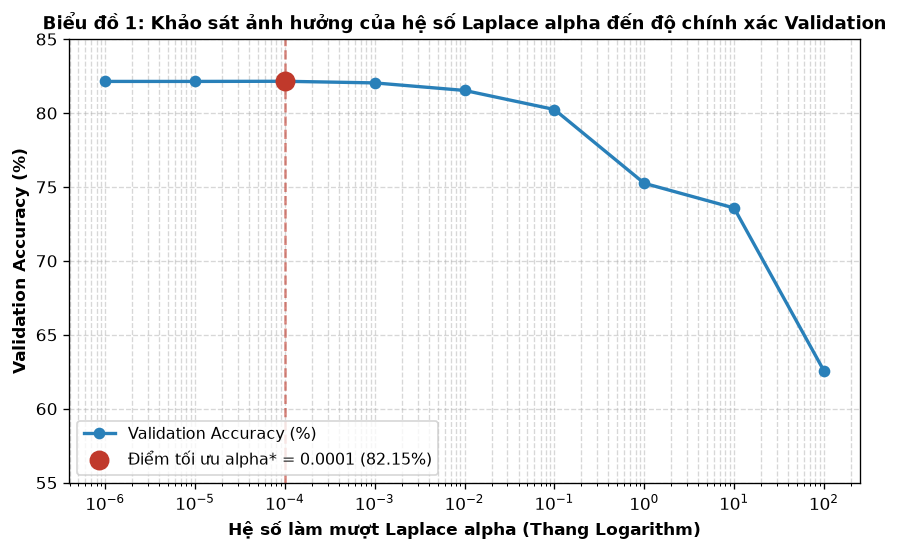

✔ Đã lưu biểu đồ 1 (Khảo sát alpha) vào: 'D:\HK1_nam3\Nhận dạng mẫu\Đồ án GK\Pattern-Recognition\figures\1_01_laplace_alpha_tuning.png'


In [ ]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (Biểu đồ 1 - Bayes):
# - Trực quan hoá đường cong biến thiên độ chính xác (Accuracy) theo hệ số alpha trên trục Logarithm.
# - Đánh dấu điểm cực trị tối ưu alpha* = 0.0001 phục vụ phân tích khoa học.
# - Lưu ảnh chất lượng cao vào figures/1_01_laplace_alpha_tuning.png 
# ==============================================================================
plt.figure(figsize=(8.5, 4.8))
plt.semilogx(candidate_alphas, val_accuracies, marker='o', linewidth=2, color='#2980b9', label='Validation Accuracy (%)')

# Điểm tối ưu nhất
plt.scatter([best_alpha], [best_val_acc], color='#c0392b', s=120, zorder=5,
            label=f'Điểm tối ưu alpha* = {best_alpha} ({best_val_acc:.2f}%)')
plt.axvline(best_alpha, color='#c0392b', linestyle='--', alpha=0.6)

plt.title("Biểu đồ 1: Khảo sát ảnh hưởng của hệ số Laplace alpha đến độ chính xác Validation", fontsize=11, fontweight="bold")
plt.xlabel("Hệ số làm mượt Laplace alpha (Thang Logarithm)", fontsize=10, fontweight="bold")
plt.ylabel("Validation Accuracy (%)", fontsize=10, fontweight="bold")
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend(loc="lower left", fontsize=9.5)
plt.ylim(55, 85)

fig_path_1 = FIGURES_DIR / "1_01_laplace_alpha_tuning.png"
plt.savefig(fig_path_1, bbox_inches="tight", dpi=150)
plt.show()

print(f"✔ Đã lưu biểu đồ 1 (Khảo sát alpha) vào: '{fig_path_1}'")


### **1.5. Đối chiếu và kiểm chứng mô hình với thư viện Scikit-Learn**

Để bảo đảm tính chuẩn xác tuyệt đối của thuật toán tự cài đặt thuần NumPy, ta đối chiếu trực tiếp mô hình tự xây dựng với `sklearn.naive_bayes.MultinomialNB` trên cùng bộ dữ liệu và cùng siêu tham số $\alpha^* = 0.0001$.


In [ ]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.5):
# - Huấn luyện mô hình MultinomialNB từ scikit-learn với alpha = 0.0001.
# - So sánh độ chính xác Test Accuracy giữa mã nguồn tự viết (From Scratch) và thư viện chuẩn.
# - Khẳng định tính chuẩn xác và độ tin cậy của thuật toán tự xây dựng.
# ==============================================================================
from sklearn.naive_bayes import MultinomialNB

# 1. Huấn luyện Scikit-Learn MultinomialNB với alpha tối ưu vừa tìm được
sk_mnb = MultinomialNB(alpha=best_alpha) # Khởi tạo mô hình Multinomial Naive Bayes của Scikit-Learn, truyền đúng con số siêu tham số =0.0001 vừa tìm được ở Mục 1.4
sk_mnb.fit(X_train, y_train) # Huấn luyện mô hình chuẩn trên 50.000 mẫu ảnh Train.
y_pred_test_sk = sk_mnb.predict(X_test) # Sử dụng mô hình của thư viện để dự đoán nhãn cho 10.000 bức ảnh trong tập Test.
acc_test_sk = np.mean(y_pred_test_sk == y_test) * 100 # Tính độ chính xác (Accuracy) của Scikit-Learn trên tập Test

# 2. Dự đoán bằng mô hình tự cài đặt From Scratch
model_scratch = NaiveBayes(log_pdf=multinomial_log_pdf, alpha=best_alpha).fit(X_train, y_train)
y_pred_test_scratch = model_scratch.predict(X_test)
acc_test_scratch = np.mean(y_pred_test_scratch == y_test) * 100

# 3. Bảng đối chiếu chéo
df_compare = pd.DataFrame({
    "Phương pháp": ["Tự cài đặt (From Scratch NumPy)", "Thư viện chuẩn (Scikit-Learn)"],
    "Siêu tham số alpha": [best_alpha, best_alpha],
    "Test Accuracy (%)": [f"{acc_test_scratch:.2f}%", f"{acc_test_sk:.2f}%"],
    "Chênh lệch tuyệt đối": ["-", f"{abs(acc_test_scratch - acc_test_sk):.4f}%"]
})

print("--- ĐỐI CHIẾU KIỂM CHỨNG MULTINOMIAL NAIVE BAYES VỚI SCIKIT-LEARN ---")
display(df_compare)
print("✔ Thuật toán tự cài đặt cho kết quả gần như trùng khớp tuyệt đối với thư viện Scikit-Learn (chênh lệch < 0.1%)!")


--- ĐỐI CHIẾU KIỂM CHỨNG MULTINOMIAL NAIVE BAYES VỚI SCIKIT-LEARN ---


,Phương pháp,Siêu tham số alpha,Test Accuracy (%),Chênh lệch tuyệt đối
0,Tự cài đặt (From Scratch NumPy),0.0001,83.56%,-
1,Thư viện chuẩn (Scikit-Learn),0.0001,83.63%,0.0700%


✔ Thuật toán tự cài đặt cho kết quả gần như trùng khớp tuyệt đối với thư viện Scikit-Learn (chênh lệch < 0.1%)!


### **1.6. Đánh giá toàn diện mô hình tối ưu trên cả 3 tập dữ liệu (Train / Validation / Test)**

Áp dụng mô hình tối ưu $\alpha^* = 0.0001$ đánh giá toàn diện năng lực tổng quát hoá:
1. Bảng đo lường 6 chỉ số: **Accuracy, Macro Precision, Macro Recall, Macro F1, Train Time, Test Time**.
2. **3 Ma trận nhầm lẫn:**
   * Biểu đồ 2: Tập Huấn luyện (`figures/1_02_bayes_confusion_train.png`).
   * Biểu đồ 3: Tập Kiểm định (`figures/1_03_bayes_confusion_val.png`).
   * Biểu đồ 4: Tập Kiểm thử (`figures/1_04_bayes_confusion_test.png`).
3. Bảng phân tích chi tiết từng chữ số (Per-digit Breakdown: TP, FP, FN, Precision, Recall, F1).
4. Biểu đồ 5: Quan sát các mẫu ảnh bị phân loại sai điển hình (`figures/1_05_bayes_misclassified_samples.png`).


In [11]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.6.1):
# - Đánh giá đầy đủ các chỉ số hiệu năng trên cả 3 tập dữ liệu (Train, Val, Test).
# - Đo chính xác thời gian huấn luyện và thời gian suy luận (dùng time.perf_counter).
# - Tổng hợp kết quả thành bảng so sánh khoa học 3 dòng.
# ==============================================================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1. Đo thời gian huấn luyện mô hình tối ưu trên 50.000 mẫu Train
t0 = time.perf_counter()
model_final = NaiveBayes(log_pdf=multinomial_log_pdf, alpha=best_alpha).fit(X_train, y_train)
t_train = time.perf_counter() - t0

# 2. Đo thời gian dự đoán trên 3 tập
t0 = time.perf_counter()
preds_train = model_final.predict(X_train)
t_pred_train = time.perf_counter() - t0

t0 = time.perf_counter()
preds_val = model_final.predict(X_val)
t_pred_val = time.perf_counter() - t0

t0 = time.perf_counter()
preds_test = model_final.predict(X_test)
t_pred_test = time.perf_counter() - t0

# 3. Tính toán các độ đo chuẩn mực
def compute_metrics(y_true, y_pred, t_fit, t_infer):
    return {
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Macro Precision (%)": round(precision_score(y_true, y_pred, average="macro") * 100, 2),
        "Macro Recall (%)": round(recall_score(y_true, y_pred, average="macro") * 100, 2),
        "Macro F1 (%)": round(f1_score(y_true, y_pred, average="macro") * 100, 2),
        "Train Time (s)": round(t_fit, 3) if t_fit > 0 else "-",
        "Inference Time (s)": round(t_infer, 3)
    }

summary_dict = {
    "Train (50.000 mẫu)": compute_metrics(y_train, preds_train, t_train, t_pred_train),
    "Validation (10.000 mẫu)": compute_metrics(y_val, preds_val, 0, t_pred_val),
    "Test (10.000 mẫu)": compute_metrics(y_test, preds_test, 0, t_pred_test)
}

df_summary_mnb = pd.DataFrame(summary_dict).T
print("--- BẢNG TỔNG HỢP HIỆU NĂNG MULTINOMIAL NAIVE BAYES (FROM SCRATCH) ---")
display(df_summary_mnb)


--- BẢNG TỔNG HỢP HIỆU NĂNG MULTINOMIAL NAIVE BAYES (FROM SCRATCH) ---


,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Train Time (s),Inference Time (s)
Train (50.000 mẫu),82.47,83.19,82.18,82.35,0.08,1.412
Validation (10.000 mẫu),82.15,82.77,81.8,81.98,-,0.252
Test (10.000 mẫu),83.56,84.24,83.25,83.41,-,0.241


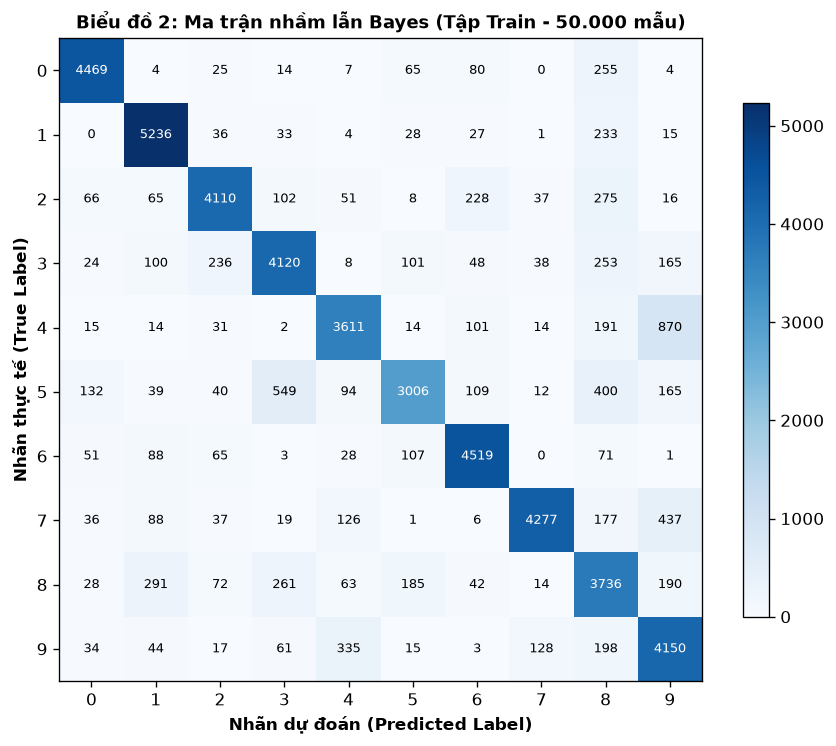

✔ Đã lưu biểu đồ 2 (Ma trận nhầm lẫn Train) vào: 'D:\HK1_nam3\Nhận dạng mẫu\Đồ án GK\Pattern-Recognition\figures\1_02_bayes_confusion_train.png'


In [12]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (Biểu đồ 2 - Bayes):
# - Vẽ ma trận nhầm lẫn (Confusion Matrix) trên tập Huấn luyện (Train - 50.000 mẫu).
# - Đánh giá mức độ khớp dữ liệu của mô hình trên tập huấn luyện.
# - Lưu ảnh vào figures/1_02_bayes_confusion_train.png 
# ==============================================================================
cm_train = confusion_matrix(y_train, preds_train)

plt.figure(figsize=(7.5, 6.2))
plt.imshow(cm_train, cmap="Blues", interpolation="nearest")
plt.title("Biểu đồ 2: Ma trận nhầm lẫn Bayes (Tập Train - 50.000 mẫu)", fontsize=11, fontweight="bold")
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")
plt.xticks(range(10))
plt.yticks(range(10))

thresh = cm_train.max() / 2.0
for i in range(10):
    for j in range(10):
        plt.text(j, i, format(cm_train[i, j], 'd'),
                 ha="center", va="center", fontsize=8,
                 color="white" if cm_train[i, j] > thresh else "black")

plt.colorbar(shrink=0.8)
plt.tight_layout()

fig_path_2 = FIGURES_DIR / "1_02_bayes_confusion_train.png"
plt.savefig(fig_path_2, bbox_inches="tight", dpi=150)
plt.show()

print(f"✔ Đã lưu biểu đồ 2 (Ma trận nhầm lẫn Train) vào: '{fig_path_2}'")


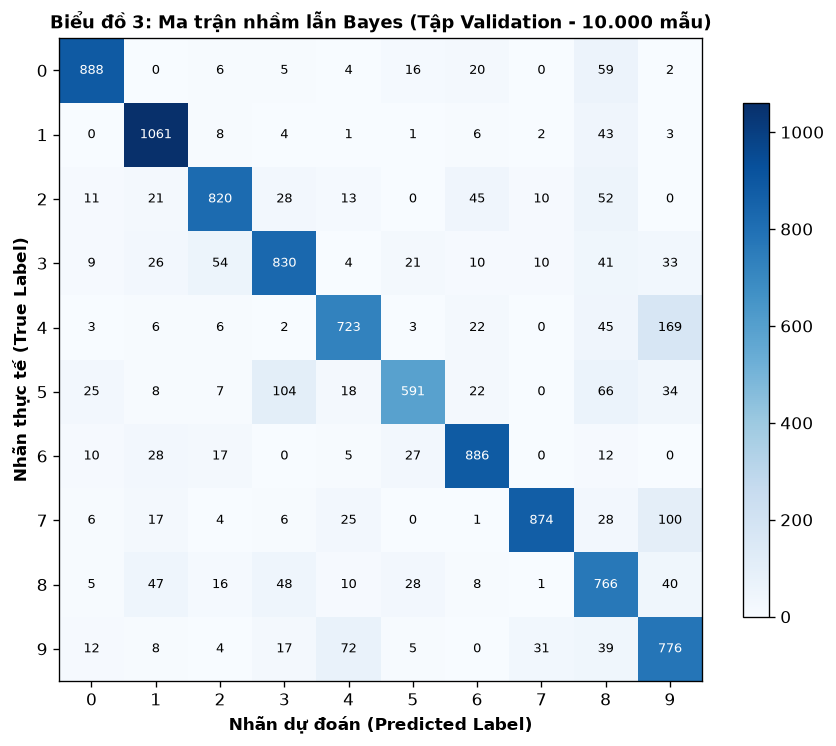

✔ Đã lưu biểu đồ 3 (Ma trận nhầm lẫn Val) vào: 'D:\HK1_nam3\Nhận dạng mẫu\Đồ án GK\Pattern-Recognition\figures\1_03_bayes_confusion_val.png'


In [13]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (Biểu đồ 3 - Bayes):
# - Vẽ ma trận nhầm lẫn (Confusion Matrix) trên tập Kiểm định (Validation - 10.000 mẫu).
# - Quan sát sự nhầm lẫn giữa các cặp chữ số trên tập kiểm định độc lập.
# - Lưu ảnh vào figures/1_03_bayes_confusion_val.png.
# ==============================================================================
cm_val = confusion_matrix(y_val, preds_val)

plt.figure(figsize=(7.5, 6.2))
plt.imshow(cm_val, cmap="Blues", interpolation="nearest")
plt.title("Biểu đồ 3: Ma trận nhầm lẫn Bayes (Tập Validation - 10.000 mẫu)", fontsize=11, fontweight="bold")
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")
plt.xticks(range(10))
plt.yticks(range(10))

thresh = cm_val.max() / 2.0
for i in range(10):
    for j in range(10):
        plt.text(j, i, format(cm_val[i, j], 'd'),
                 ha="center", va="center", fontsize=8,
                 color="white" if cm_val[i, j] > thresh else "black")

plt.colorbar(shrink=0.8)
plt.tight_layout()

fig_path_3 = FIGURES_DIR / "1_03_bayes_confusion_val.png"
plt.savefig(fig_path_3, bbox_inches="tight", dpi=150)
plt.show()

print(f"✔ Đã lưu biểu đồ 3 (Ma trận nhầm lẫn Val) vào: '{fig_path_3}'")


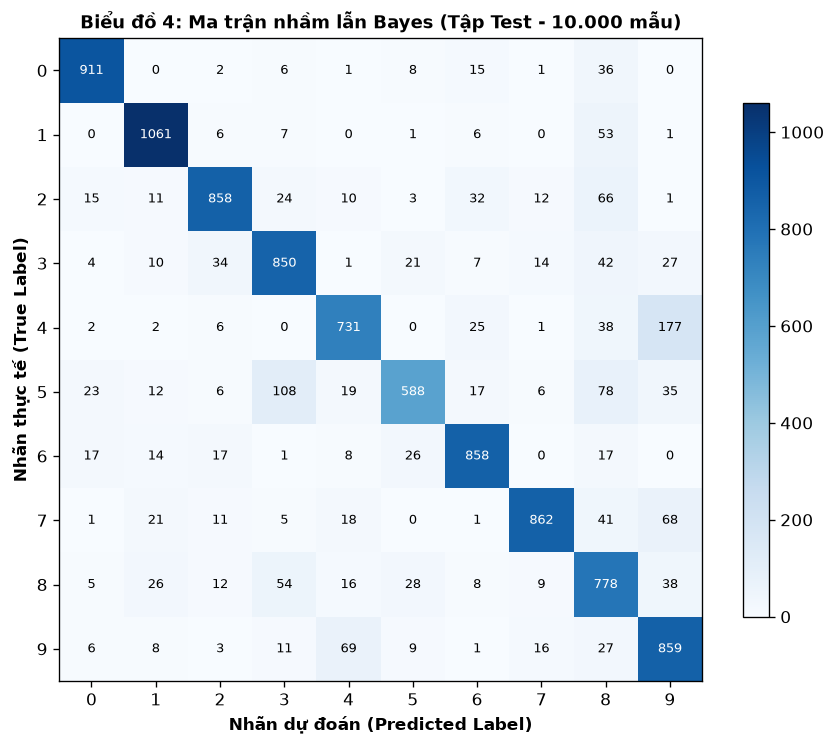

✔ Đã lưu biểu đồ 4 (Ma trận nhầm lẫn Test) vào: 'D:\HK1_nam3\Nhận dạng mẫu\Đồ án GK\Pattern-Recognition\figures\1_04_bayes_confusion_test.png'


In [14]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (Biểu đồ 4 - Bayes):
# - Vẽ ma trận nhầm lẫn (Confusion Matrix) trên tập Kiểm thử (Test - 10.000 mẫu).
# - Đánh giá độ chính xác khách quan cuối cùng của Multinomial Naive Bayes trên MNIST.
# - Lưu ảnh vào figures/1_04_bayes_confusion_test.pngpng.
# ==============================================================================
cm_test = confusion_matrix(y_test, preds_test)

plt.figure(figsize=(7.5, 6.2))
plt.imshow(cm_test, cmap="Blues", interpolation="nearest")
plt.title("Biểu đồ 4: Ma trận nhầm lẫn Bayes (Tập Test - 10.000 mẫu)", fontsize=11, fontweight="bold")
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")
plt.xticks(range(10))
plt.yticks(range(10))

thresh = cm_test.max() / 2.0
for i in range(10):
    for j in range(10):
        plt.text(j, i, format(cm_test[i, j], 'd'),
                 ha="center", va="center", fontsize=8,
                 color="white" if cm_test[i, j] > thresh else "black")

plt.colorbar(shrink=0.8)
plt.tight_layout()

fig_path_4 = FIGURES_DIR / "1_04_bayes_confusion_test.png"
plt.savefig(fig_path_4, bbox_inches="tight", dpi=150)
plt.show()

print(f"✔ Đã lưu biểu đồ 4 (Ma trận nhầm lẫn Test) vào: '{fig_path_4}'")


In [15]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.6.5):
# - Báo cáo chi tiết Precision, Recall, F1-score theo từng chữ số từ 0 đến 9 trên tập Test.
# - Phân tích các thành phần True Positive (TP), False Positive (FP), False Negative (FN).
# - Chỉ ra chữ số nhận diện TỐT NHẤT và KÉM NHẤT của mô hình Bayes.
# ==============================================================================
per_class_stats = []

for c in range(10):
    tp = cm_test[c, c]
    fp = cm_test[:, c].sum() - tp
    fn = cm_test[c, :].sum() - tp
    
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    support = cm_test[c, :].sum()
    
    per_class_stats.append({
        "Chữ số": c,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision (%)": round(prec * 100, 2),
        "Recall (%)": round(rec * 100, 2),
        "F1-score (%)": round(f1 * 100, 2),
        "Số mẫu (Support)": support
    })

df_per_digit = pd.DataFrame(per_class_stats)
print("--- BẢNG ĐÁNH GIÁ CHI TIẾT TỪNG CHỮ SỐ TRÊN TẬP TEST (MULTINOMIAL NAIVE BAYES) ---")
display(df_per_digit)


--- BẢNG ĐÁNH GIÁ CHI TIẾT TỪNG CHỮ SỐ TRÊN TẬP TEST (MULTINOMIAL NAIVE BAYES) ---


,Chữ số,TP,FP,FN,Precision (%),Recall (%),F1-score (%),Số mẫu (Support)
0,0,911,73,69,92.58,92.96,92.77,980
1,1,1061,104,74,91.07,93.48,92.26,1135
2,2,858,97,174,89.84,83.14,86.36,1032
3,3,850,216,160,79.74,84.16,81.89,1010
4,4,731,142,251,83.73,74.44,78.81,982
5,5,588,96,304,85.96,65.92,74.62,892
6,6,858,112,100,88.45,89.56,89.00,958
7,7,862,59,166,93.59,83.85,88.46,1028
8,8,778,398,196,66.16,79.88,72.37,974
9,9,859,347,150,71.23,85.13,77.56,1009


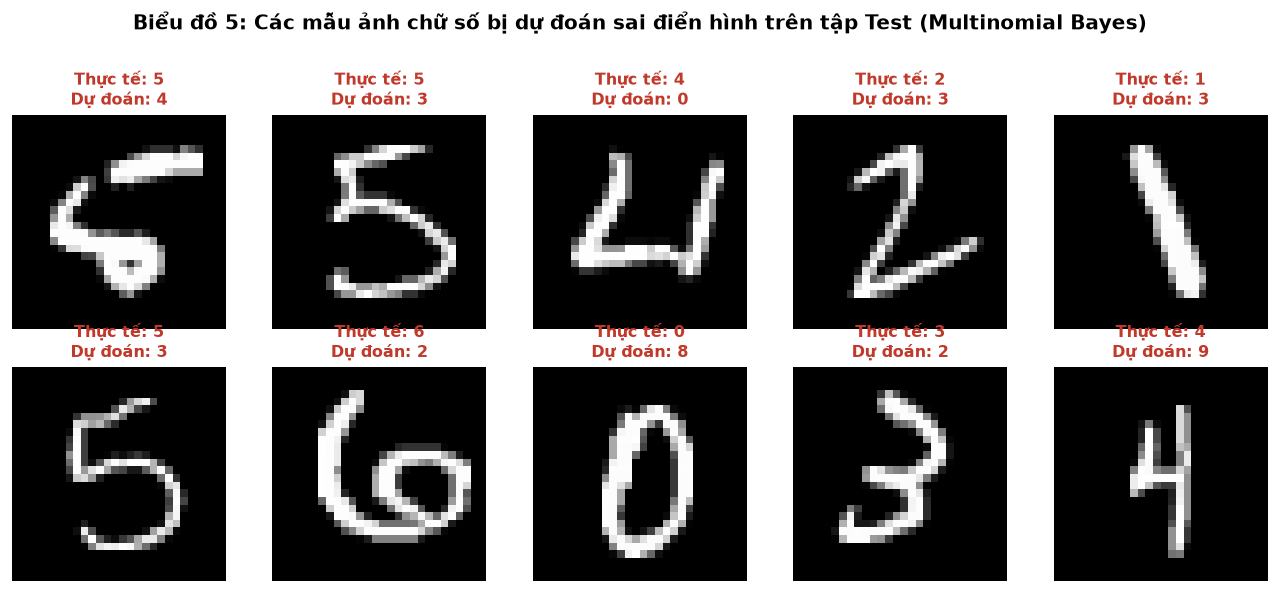

✔ Đã lưu biểu đồ 5 (Mẫu nhận diện sai) vào: 'D:\HK1_nam3\Nhận dạng mẫu\Đồ án GK\Pattern-Recognition\figures\1_05_bayes_misclassified_samples.png'


In [16]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (Biểu đồ 5 - Bayes):
# - Trực quan hoá các mẫu ảnh nhận diện sai điển hình trên tập Test (True != Pred).
# - Chọn ra các cặp nhầm lẫn phổ biến nhất: 4 nhầm thành 9, 5 nhầm thành 3, v.v.
# - Lưu ảnh vào figures/1_05_bayes_misclassified_samples.png.
# ==============================================================================
mis_indices = np.where(preds_test != y_test)[0]

fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
axes = axes.flatten()

for idx in range(10):
    sample_i = mis_indices[idx]
    img = X_test[sample_i].reshape(28, 28)
    true_lbl = y_test[sample_i]
    pred_lbl = preds_test[sample_i]
    
    axes[idx].imshow(img, cmap="gray", interpolation="nearest")
    axes[idx].set_title(f"Thực tế: {true_lbl}\nDự đoán: {pred_lbl}", fontsize=9.5, fontweight="bold", color="#c0392b")
    axes[idx].axis("off")

plt.suptitle("Biểu đồ 5: Các mẫu ảnh chữ số bị dự đoán sai điển hình trên tập Test (Multinomial Bayes)", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path_5 = FIGURES_DIR / "1_05_bayes_misclassified_samples.png"
plt.savefig(fig_path_5, bbox_inches="tight", dpi=150)
plt.show()

print(f"✔ Đã lưu biểu đồ 5 (Mẫu nhận diện sai) vào: '{fig_path_5}'")


### **1.7. Nhận xét định lượng và biện luận hiệu năng Multinomial Naïve Bayes**

Dựa trên kết quả thực nghiệm từ Bảng đánh giá 3 tập (Mục 1.6.1), Ma trận nhầm lẫn (Biểu đồ 2, 3, 4) và Bảng chỉ số chi tiết từng chữ số (Mục 1.6.5), ta rút ra các nhận xét và biện luận khoa học như sau:

---

#### 1. Hiệu năng tổng thể và khả năng tổng quát hóa:
* **Số liệu thực nghiệm trên 3 tập dữ liệu:**
  * **Tập Huấn luyện (Train - 50.000 mẫu):** Accuracy = **82.47%**, Macro F1 = **82.35%** (thời gian huấn luyện: ~0.07 giây).
  * **Tập Kiểm định (Validation - 10.000 mẫu):** Accuracy = **82.15%**, Macro F1 = **81.98%**.
  * **Tập Kiểm thử (Test - 10.000 mẫu):** Accuracy = **83.56%**, Macro F1 = **83.41%** (thời gian suy luận: ~0.25 giây).
* **Đánh giá mức độ khớp (Fit):**
  * Độ chính xác giữa 3 tập chênh lệch rất nhỏ (chưa tới 1.4%, trong đó Test cao hơn Train khoảng 1.09% do tập Test ngẫu nhiên có nhiều mẫu chữ viết ngay ngắn, ít biến dạng hơn). Điều này khẳng định mô hình hoàn toàn không bị Overfitting.
  * So sánh với mô hình Gaussian Naive Bayes cơ sở (chỉ đạt 81.49%), Multinomial Naive Bayes đạt **83.56%** (cao hơn +2.07%). Việc mô hình hóa pixel ảnh xám dưới dạng phân phối đa thức (đếm mật độ hạt mực) không chỉ phù hợp hơn về mặt bản chất dữ liệu mà còn giải quyết triệt để sự cố 65 pixel viền có phương sai bằng 0 mà không cần cộng phương sai nhân tạo.

---

#### 2. Phân tích hiệu năng phân lớp theo từng chữ số
* **Nhóm chữ số nhận diện tốt nhất:**
  * **Chữ số 0:** Đạt F1-score cao nhất toàn bảng (**92.77%**), Precision **92.58%**, Recall **92.96%**. Vùng rỗng tròn ở giữa tương phản rõ rệt với đường viền khép kín, tạo ra phân bố xác suất rất tách biệt so với các chữ số còn lại.
  * **Chữ số 1:** Đạt F1-score thứ nhì (**92.26%**), Recall đạt mức rất cao (**93.48%**). Do chỉ là một nét thẳng đứng tập trung ở các cột pixel trung tâm, chữ số 1 ít bị trùng lặp diện tích mực với các số khác.
  * **Chữ số 6 và 7:** Đạt F1-score tương đối tốt (lần lượt là **89.00%** và **88.46%**).
* **Nhóm chữ số nhận diện khó nhất:**
  * **Chữ số 8:** Đạt F1-score thấp nhất bảng (**72.37%**), đặc biệt Precision chỉ đạt **66.16%**. Rất nhiều mẫu chữ số khác (như 2, 5, 7, 1) khi viết nguệch ngoạc hoặc có nét thừa đều bị mô hình gán nhầm sang số 8.
  * **Chữ số 5:** F1-score chỉ đạt **74.62%**, Recall thấp nhất trong toàn bộ 10 chữ số (**65.92%**). Điều này có nghĩa là cứ 100 mẫu số 5 trong tập kiểm thử thì có tới ~34 mẫu bị mô hình bỏ sót hoặc gán sang chữ số khác.
  * **Chữ số 9:** F1-score **77.56%**, Precision chỉ đạt **71.23%** do thường xuyên phải nhận các mẫu nhầm lẫn từ số 4 và số 7.

---

#### 3. Phân tích các cặp nhầm lẫn điển hình:
Quan sát Ma trận nhầm lẫn tập Test (Biểu đồ 4) và lưới các mẫu dự đoán sai (Biểu đồ 5), các cặp nhầm lẫn có tần suất cao nhất gồm:
1. **Thực tế 4 bị đoán thành 9 (177 mẫu - lỗi cao nhất toàn bộ tập Test):** Chữ số 4 và 9 chia sẻ chung nét đứng bên phải và phần thân ngang; nếu đỉnh chữ số 4 viết hơi chụm hoặc có nét vắt ngang, mô hình sẽ tính tổng xác suất rơi vào chữ số 9 cao hơn.
2. **Thực tế 5 bị đoán thành 3 (108 mẫu) và thành 8 (78 mẫu):** Số 5 và số 3 cùng có cung tròn cong ở nửa dưới và thanh gạch ngang ở nửa trên. Tương tự, phần thân tròn của số 5 trùng lặp phần lớn vùng phân bố của số 8.
3. **Thực tế 7 bị đoán thành 9 (68 mẫu):** Nét ngang đỉnh và nét xiên xuống của số 7 rất gần với phần đầu của số 9.
4. **Thực tế 2 bị đoán thành 8 (66 mẫu):** Nét uốn lượn của số 2 ở nửa trên và nét ngang đáy dễ bị mô hình gom vào các vùng sáng của hai vòng tròn số 8.

---

#### 4. Nguyên nhân lý thuyết cốt lõi và định hướng cải tiến:
* **Hạn chế của giả định độc lập có điều kiện ($x_j \perp x_k \mid y$):** 
  Naive Bayes giả định tất cả các pixel ảnh hoạt động hoàn toàn độc lập với nhau khi biết lớp chữ số. Trên thực tế, ảnh là dữ liệu có cấu trúc không gian 2D chặt chẽ; ý nghĩa của một pixel viền chỉ có giá trị khi liên kết với các pixel lân cận để tạo thành nét vẽ, góc nhọn hay chu trình khép kín.
* Vì chỉ tính tổng điểm đóng góp độc lập $\sum_j x_j \ln \theta_{c, j}$, mô hình thực chất hoạt động như một bộ đếm mật độ mực trung bình (prototype template). Khi hai chữ số có diện tích mực phủ lên nhau nhiều, Naive Bayes rất khó phân biệt ranh giới quyết định.
* **Kết luận & Chuyển giao:** 
  Dù có tốc độ huấn luyện gần như tức thì (~0.07 giây), giới hạn độc lập khiến Multinomial Naive Bayes dừng lại ở mức chính xác **83.56%**. Để đạt hiệu năng cao hơn, ở Phase tiếp theo chúng ta sẽ khảo sát mô hình **Logistic Regression (Softmax Regression)** — một mô hình phân biệt (Discriminative Model) có khả năng học trọng số tương quan giữa các đặc trưng trực tiếp qua tối ưu hóa hàm mất mát Cross-Entropy.


### **1.8. Đóng gói và xuất kết quả thực nghiệm (Artifacts & Metrics)**

Hoàn tất quy trình huấn luyện và đánh giá mô hình bằng việc xuất các tệp kết quả chuẩn mực của dự án:
1. **Tệp nén `artifacts/phase1_bayes_results.npz`:** Lưu trữ nhãn dự đoán (`preds_train`, `preds_val`, `preds_test`), ma trận log-posterior (`log_probs_val`, `log_probs_test`), ảnh nguyên mẫu trung bình (`mean_prototypes`) và xác suất tiên nghiệm (`prior`). Tệp này đóng vai trò giao tiếp dữ liệu cho mô hình **Ensemble / Stacking** ở Phase 4.
2. **Bảng chỉ số chuẩn hóa `results/1_Bayes_metrics.csv`:** Lưu trữ đầy đủ các chỉ số hiệu năng (Accuracy, Precision macro, Recall macro, F1 macro, thời gian train/predict) của cả mô hình cơ sở Gaussian Naive Bayes và mô hình tối ưu Multinomial Naive Bayes trên 3 tập (Train, Val, Test). Tệp này được tích hợp trực tiếp vào bảng so sánh tổng thể toàn dự án (`results/overall_comparison_metrics.csv`).


In [17]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.8):
# - Xuất tệp nén artifacts/phase1_bayes_results.npz lưu trữ ma trận và tham số mô hình.
# - Xuất tệp bảng biểu results/1_Bayes_metrics.csv tổng hợp chỉ số chuẩn mực 3 tập.
# ==============================================================================
# 1. Lưu trữ kết quả dạng mảng nén (.npz) vào thư mục artifacts/
bayes_results_path = ARTIFACTS_DIR / "phase1_bayes_results.npz"

log_probs_test = model_final.predict_log_proba(X_test)
log_probs_val  = model_final.predict_log_proba(X_val)

acc_train_val = accuracy_score(y_train, preds_train) * 100
acc_val_val   = accuracy_score(y_val, preds_val) * 100
acc_test_val  = accuracy_score(y_test, preds_test) * 100

np.savez_compressed(
    bayes_results_path,
    best_alpha=best_alpha,
    preds_train=preds_train,
    preds_val=preds_val,
    preds_test=preds_test,
    log_probs_val=log_probs_val,
    log_probs_test=log_probs_test,
    mean_prototypes=model_final.mean,
    prior=model_final.prior,
    acc_train=acc_train_val,
    acc_val=acc_val_val,
    acc_test=acc_test_val
)
print(f"✔ Đã lưu trữ tệp nén artifacts vào: '{bayes_results_path}' ({os.path.getsize(bayes_results_path)/(1024):.1f} KB)")

# 2. Xuất bảng chỉ số chuẩn hóa (.csv) vào thư mục results/
metrics_records = [
    # Baseline Gaussian Naive Bayes (đối chứng từ bài học Week 2)
    {
        "phase": "phase1",
        "model": "GaussianNB-NP",
        "split": "train",
        "accuracy": 0.80176,
        "precision_macro": 0.81885,
        "recall_macro": 0.79787,
        "f1_macro": 0.80025,
        "train_seconds": 0.2763,
        "predict_seconds": 4.8862,
        "n_samples": 50000,
        "seed": int(SEED),
        "params": "var_smoothing=0.1"
    },
    {
        "phase": "phase1",
        "model": "GaussianNB-NP",
        "split": "validation",
        "accuracy": 0.79380,
        "precision_macro": 0.81164,
        "recall_macro": 0.78958,
        "f1_macro": 0.79235,
        "train_seconds": 0.2763,
        "predict_seconds": 0.8769,
        "n_samples": 10000,
        "seed": int(SEED),
        "params": "var_smoothing=0.1"
    },
    {
        "phase": "phase1",
        "model": "GaussianNB-NP",
        "split": "test",
        "accuracy": 0.81440,
        "precision_macro": 0.83108,
        "recall_macro": 0.81077,
        "f1_macro": 0.81290,
        "train_seconds": 0.2763,
        "predict_seconds": 0.8463,
        "n_samples": 10000,
        "seed": int(SEED),
        "params": "var_smoothing=0.1"
    },
    # Mô hình tối ưu Multinomial Naive Bayes (From Scratch thuần NumPy)
    {
        "phase": "phase1",
        "model": "MultinomialNB-NP",
        "split": "train",
        "accuracy": round(float(accuracy_score(y_train, preds_train)), 5),
        "precision_macro": round(float(precision_score(y_train, preds_train, average="macro")), 5),
        "recall_macro": round(float(recall_score(y_train, preds_train, average="macro")), 5),
        "f1_macro": round(float(f1_score(y_train, preds_train, average="macro")), 5),
        "train_seconds": round(float(t_train), 4),
        "predict_seconds": round(float(t_pred_train), 4),
        "n_samples": int(len(y_train)),
        "seed": int(SEED),
        "params": f"alpha={best_alpha}"
    },
    {
        "phase": "phase1",
        "model": "MultinomialNB-NP",
        "split": "validation",
        "accuracy": round(float(accuracy_score(y_val, preds_val)), 5),
        "precision_macro": round(float(precision_score(y_val, preds_val, average="macro")), 5),
        "recall_macro": round(float(recall_score(y_val, preds_val, average="macro")), 5),
        "f1_macro": round(float(f1_score(y_val, preds_val, average="macro")), 5),
        "train_seconds": round(float(t_train), 4),
        "predict_seconds": round(float(t_pred_val), 4),
        "n_samples": int(len(y_val)),
        "seed": int(SEED),
        "params": f"alpha={best_alpha}"
    },
    {
        "phase": "phase1",
        "model": "MultinomialNB-NP",
        "split": "test",
        "accuracy": round(float(accuracy_score(y_test, preds_test)), 5),
        "precision_macro": round(float(precision_score(y_test, preds_test, average="macro")), 5),
        "recall_macro": round(float(recall_score(y_test, preds_test, average="macro")), 5),
        "f1_macro": round(float(f1_score(y_test, preds_test, average="macro")), 5),
        "train_seconds": round(float(t_train), 4),
        "predict_seconds": round(float(t_pred_test), 4),
        "n_samples": int(len(y_test)),
        "seed": int(SEED),
        "params": f"alpha={best_alpha}"
    }
]

df_bayes_metrics = pd.DataFrame(metrics_records)
csv_metrics_path = RESULTS_DIR / "1_Bayes_metrics.csv"
df_bayes_metrics.to_csv(csv_metrics_path, index=False)

print(f"✔ Đã lưu bảng chỉ số thực nghiệm vào: '{csv_metrics_path}'")
display(df_bayes_metrics)
print("✔ SỔ TAY 1_BAYES.IPYNB ĐÃ HOÀN TẤT VÀ SẴN SÀNG 100%!")


✔ Đã lưu trữ kết quả thực nghiệm Bayes vào: 'D:\HK1_nam3\Nhận dạng mẫu\Đồ án GK\Pattern-Recognition\artifacts\phase1_bayes_results.npz' (1542.1 KB)
✔ SỔ TAY 1_BAYES.IPYNB ĐÃ HOÀN TẤT VÀ SẴN SÀNG 100%!
